# ✈️ Try AeroGuard: watch an engine fail, 40 flights in advance

This notebook sends a real NASA N-CMAPSS test engine, flight by flight, to the **live AeroGuard API**.
The engine was never seen during training. Watch the decision move from `OK` to `WATCH` to `URGENT` before the failure.

Just click **Runtime → Run all**. The free server may need about a minute to wake up.

- Code: https://github.com/RayenSansa03/aeroguard
- API docs: https://aeroguard-api-75tq.onrender.com/docs

In [7]:
import time
import uuid
from collections import Counter

import matplotlib.pyplot as plt
import pandas as pd
import requests
from matplotlib.patches import Patch

API_URL = "https://aeroguard-api-75tq.onrender.com"


def wait_for_api(timeout=240):
    """The free server sleeps when idle: retry until it answers."""
    start = time.time()
    while time.time() - start < timeout:
        try:
            response = requests.get(f"{API_URL}/health", timeout=30)
            if response.ok:
                return response.json()
        except requests.RequestException:
            pass
        print("Waking up the free server...")
        time.sleep(10)
    raise RuntimeError("The API did not answer. Please try again in a minute.")


print("API ready:", wait_for_api())

API ready: {'statut': 'ok', 'version': '7.1.0', 'inference': 'onnx', 'modeles_charges': True, 'mlflow': 'non configuré'}


In [8]:
DATA_URL = (
    "https://github.com/RayenSansa03/aeroguard/releases/download/"
    "v7.1.0/demo_engine_DS02_14.csv"
)

flights = pd.read_csv(DATA_URL)
feature_columns = [c for c in flights.columns if c not in ("cycle", "RUL")]

print(f"{len(flights)} flights, {len(feature_columns)} features per flight")
flights[["cycle", "RUL"] + feature_columns[:4]].head()

76 flights, 126 features per flight


,cycle,RUL,T24_mean_montee,T24_mean_croisiere,T24_mean_descente,T24_std_montee
0,1,75,NaN,-0.050571,NaN,NaN
1,2,74,-0.003600,-0.027631,-0.002191,0.021855
2,3,73,-0.035445,0.039728,0.009761,0.018760
3,4,72,NaN,0.039304,NaN,NaN
4,5,71,0.043924,0.115625,0.050759,0.018903


In [9]:
ENGINE_ID = f"COLAB-{uuid.uuid4().hex[:6]}"  # unique id, so visitors never mix their engines
session = requests.Session()
decisions = []
previous_level = None

print(f"Engine {ENGINE_ID}: the first call can take ~30 s (models are loading)\n")
for _, row in flights.iterrows():
    measurements = {
        name: None if pd.isna(row[name]) else float(row[name]) for name in feature_columns
    }
    payload = {"engine": ENGINE_ID, "cycle": int(row["cycle"]), "measurements": measurements}
    response = session.post(f"{API_URL}/fleet/flights", json=payload, timeout=120)
    response.raise_for_status()

    decision = response.json()
    decision["flights_before_failure"] = int(row["RUL"])
    decisions.append(decision)

    if decision["level"] != previous_level:  # print only when the level changes
        print(
            f"Flight {decision['cycle']:>3} | {decision['flights_before_failure']:>3} flights "
            f"before failure | {decision['level']:<6} | {decision['message']}"
        )
        previous_level = decision["level"]

results = pd.DataFrame(decisions)

Engine COLAB-c93999: the first call can take ~30 s (models are loading)

Flight   1 |  75 flights before failure | OK     | No confirmed alert: normal operation.
Flight   9 |  67 flights before failure | URGENT | Known wear detected (probability 96%).
Flight  11 |  65 flights before failure | OK     | No confirmed alert: normal operation.
Flight  15 |  61 flights before failure | URGENT | Known wear detected (probability 96%).
Flight  16 |  60 flights before failure | WATCH  | Known wear detected (probability 94%).
Flight  18 |  58 flights before failure | URGENT | Known wear detected (probability 95%).
Flight  22 |  54 flights before failure | WATCH  | Unknown anomaly confirmed: inspect the engine (sensors: P50, P15).
Flight  24 |  52 flights before failure | OK     | No confirmed alert: normal operation.
Flight  25 |  51 flights before failure | WATCH  | Known wear detected (probability 93%).
Flight  26 |  50 flights before failure | URGENT | Known wear detected (probability 97%).
Fl

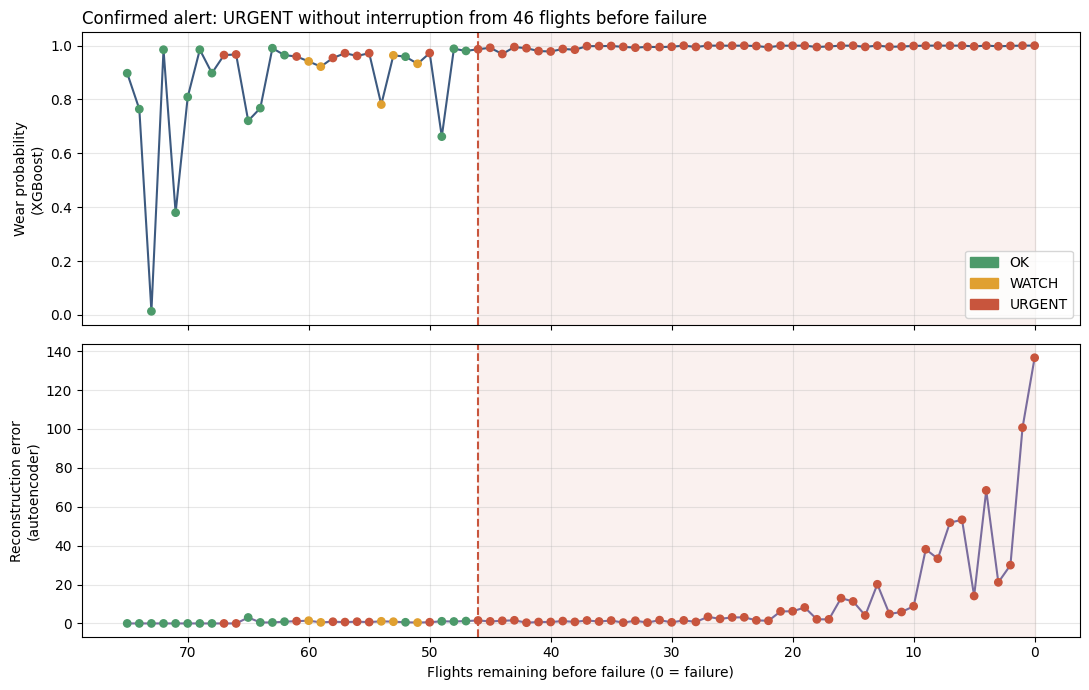

In [10]:
COLORS = {"OK": "#4C9A6A", "WATCH": "#E0A030", "URGENT": "#C8553D"}

# Confirmed alert = first flight from which the engine stays URGENT until the end
is_urgent = (results["level"] == "URGENT").to_numpy()
last_not_urgent = [i for i, urgent in enumerate(is_urgent) if not urgent]
start = last_not_urgent[-1] + 1 if last_not_urgent else 0
confirmed = int(results["flights_before_failure"].iloc[start]) if start < len(results) else None

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
x = results["flights_before_failure"]
point_colors = results["level"].map(COLORS)

ax1.plot(x, results["wear_probability"], color="#3D5A80", lw=1.5)
ax1.scatter(x, results["wear_probability"], c=point_colors, s=28, zorder=3)
ax1.set_ylabel("Wear probability\n(XGBoost)")

ax2.plot(x, results["reconstruction_error"], color="#7A6C9D", lw=1.5)
ax2.scatter(x, results["reconstruction_error"], c=point_colors, s=28, zorder=3)
ax2.set_ylabel("Reconstruction error\n(autoencoder)")
ax2.set_xlabel("Flights remaining before failure (0 = failure)")
ax2.invert_xaxis()  # time flows left to right

if confirmed is not None:
    for ax in (ax1, ax2):
        ax.axvspan(confirmed, 0, color=COLORS["URGENT"], alpha=0.08)
        ax.axvline(confirmed, ls="--", color=COLORS["URGENT"])
    ax1.set_title(
        f"Confirmed alert: URGENT without interruption from {confirmed} flights before failure",
        loc="left",
    )

ax1.legend(
    handles=[Patch(color=color, label=level) for level, color in COLORS.items()],
    loc="lower right",
)
for ax in (ax1, ax2):
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [11]:
def first_flight(level):
    rows = results[results["level"] == level]
    return None if rows.empty else int(rows["flights_before_failure"].iloc[0])

sensors = Counter(s for row in results["sensors"] for s in row)

print(f"First early signal  : {first_flight('URGENT')} flights before failure (isolated, not yet stable)")
print(f"Confirmed alert     : {confirmed} flights before failure (stays URGENT until the end)")
print("Sensors to inspect  :", ", ".join(s for s, _ in sensors.most_common(3)) or "none")
print("\nLast decision:", results.iloc[-1]["message"])

First early signal  : 67 flights before failure (isolated, not yet stable)
Confirmed alert     : 46 flights before failure (stays URGENT until the end)
Sensors to inspect  : T48, T50, P24

Last decision: Wear confirmed by both models: priority maintenance.


In [12]:
response = session.delete(f"{API_URL}/fleet/engines/{ENGINE_ID}", timeout=30)
print("Demo engine removed from the live API:", response.json())

Demo engine removed from the live API: {'engine': 'COLAB-c93999', 'status': 'reset'}


## What you just saw

- **Early signals** (first flights): XGBoost already sees signs of wear, but they come and go. These are warnings to watch, not yet a decision.
- **Confirmed alert**: once both models agree, the engine stays `URGENT` until the failure, here about 46 flights in advance, enough time to plan maintenance.
- **Two complementary models**: XGBoost recognizes known wear patterns; the autoencoder (flat for the first 10 flights, its per-engine baseline) flags anything unusual and rises sharply near the failure.
- On the 39 NASA test engines, the system warned **39 / 39 engines about 40 flights before failure**.

Full project, results and architecture: https://github.com/RayenSansa03/aeroguard